# Benchmark Analysis

This notebook reads the CSV files produced by the benchmark scripts in `benchmarks/` and turns them into the tables and figures of the experimental chapter.

It performs **no computation**: the runs are done once by the scripts, and this notebook only loads and presents their output. Run the scripts first:

```
python benchmarks/computation_time.py
python benchmarks/memory_usage.py
python benchmarks/effect_geometry.py
python benchmarks/effect_filtration_scope.py
```

## 1. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from persistent_homology.plotting import plot_loglog_scaling

RESULTS = '../benchmarks/results'
FIGURES = '../figures'

## 2. Computation Time

Wall-clock time on the noisy circle as the number of points grows.

In [2]:
time_df = pd.read_csv(f'{RESULTS}/computation_time.csv')
exp_df = pd.read_csv(f'{RESULTS}/scaling_exponents.csv')

Saved -> ../figures/loglog_time_cube.png


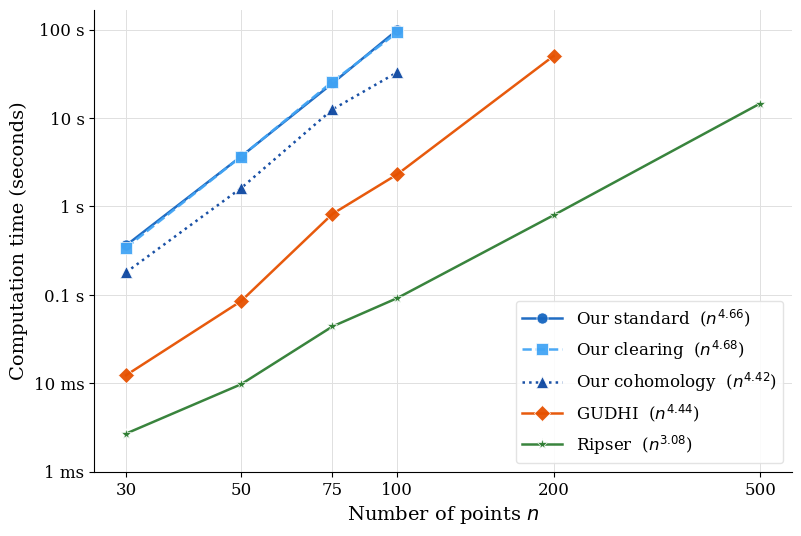

In [8]:
DATASET = 'Cube'  # Choose from: "Circle", "Sphere", "Torus", "Cube".

# Filter both tables to the chosen dataset.
time_df_filtered = time_df[time_df['dataset'] == DATASET]
exp_df_filtered  = exp_df[exp_df['dataset']  == DATASET]
exponents = dict(zip(exp_df_filtered['method'], exp_df_filtered['exponent']))

# Time table for the chosen dataset.
time_table = time_df_filtered.pivot(index='method', columns='n', values='time_s')

ax = plot_loglog_scaling(
    time_df_filtered,
    quantity='time',
    exponents=exponents,
    title=f'', # Computation time, {DATASET}
    savepath=f'{FIGURES}/loglog_time_{DATASET.lower()}.png',
)
plt.show()

## 3. Memory Usage

Peak memory of our three implementations (Python-level allocations).

In [9]:
mem_df = pd.read_csv(f'{RESULTS}/memory_usage.csv')
exp_mem_df = pd.read_csv(f'{RESULTS}/scaling_exponents_memory.csv')
mem_df.head()

,dataset,method,n,peak_mb
0,Circle,our_standard,30,1.615187
1,Circle,our_clearing,30,1.611732
2,Circle,our_cohomology,30,2.314377
3,Circle,our_standard,50,8.605972
4,Circle,our_clearing,50,8.590862


Saved -> ../figures/loglog_memory_cube.png


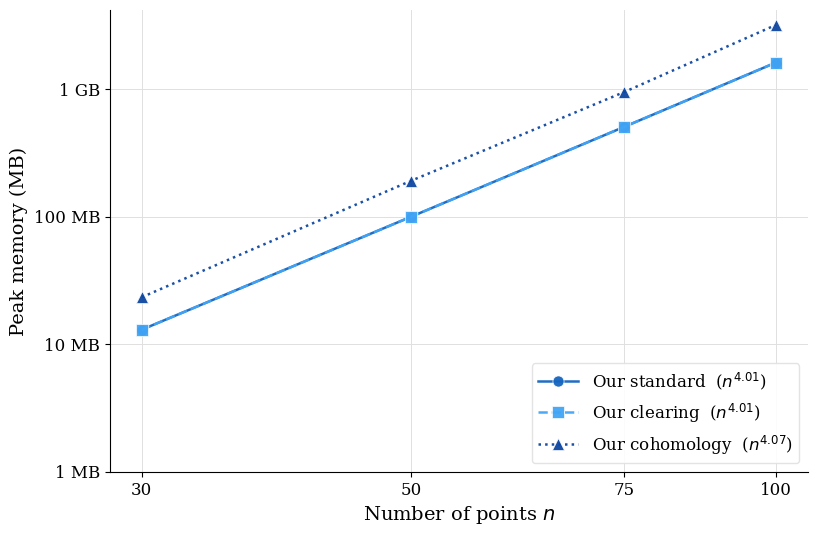

In [ ]:
DATASET = 'Cube'  # Choose from: "Circle", "Sphere", "Torus", "Cube".

mem_df_filtered = mem_df[mem_df['dataset'] == DATASET]
exp_mem_df_filtered  = exp_mem_df[exp_mem_df['dataset']  == DATASET]
exponents_mem  = dict(zip(exp_mem_df_filtered['method'], exp_mem_df_filtered['exponent']))
mem_table = mem_df_filtered.pivot(index='method', columns='n', values='peak_mb')

ax = plot_loglog_scaling(
    mem_df_filtered,
    quantity='memory',
    exponents=exponents_mem,
    title=f'', # Memory usage, {DATASET}
    savepath=f'{FIGURES}/loglog_memory_{DATASET.lower()}.png',
)
plt.show()

## 4. Effect of the Filtration Scope

Computation time at fixed $n = 100$ on the circle, as $\varepsilon_{\max}$ grows.

In [20]:
scope_df = pd.read_csv(f'{RESULTS}/effect_filtration_scope.csv')
scope_df.head()

,dataset,method,max_eps,time_s,pairs
0,Circle,our_standard,0.5,0.245787,526
1,Circle,our_clearing,0.5,0.243984,526
2,Circle,our_cohomology,0.5,0.244740,526
3,Circle,GUDHI,0.5,0.000344,50
4,Circle,Ripser,0.5,0.000648,50


Saved -> ../figures/scope_time_circle.png


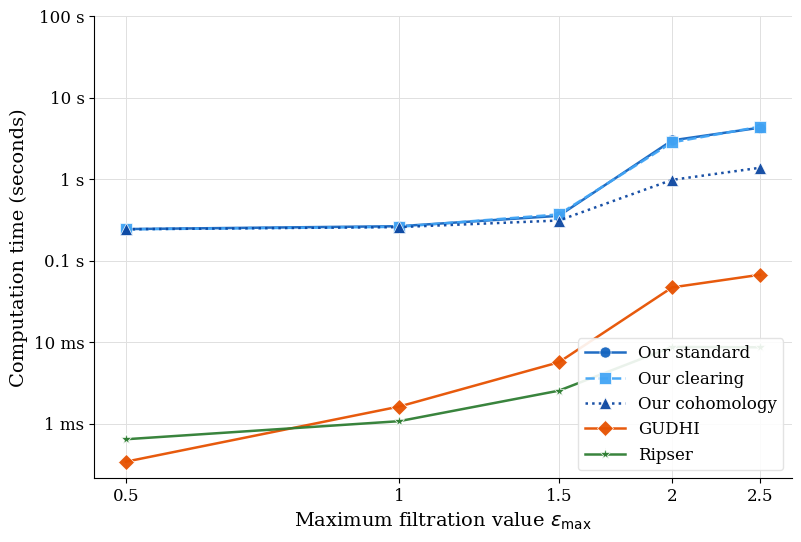

Saved -> ../figures/scope_time_sphere.png


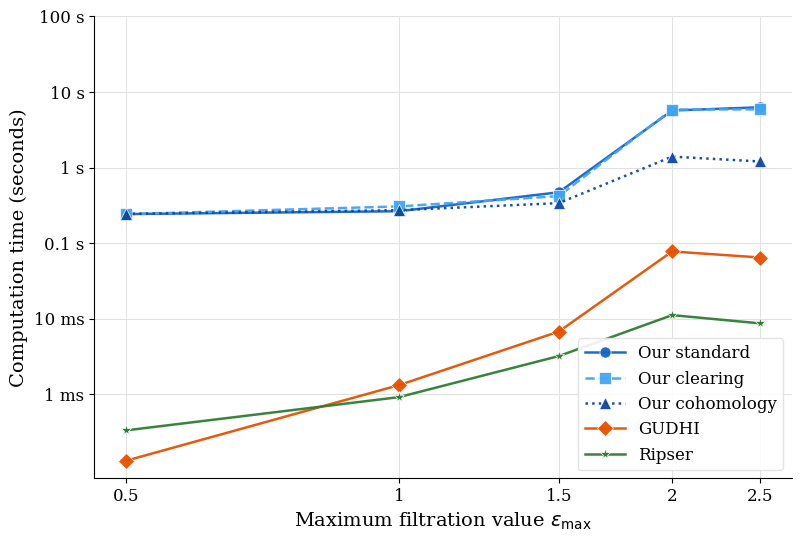

Saved -> ../figures/scope_time_torus.png


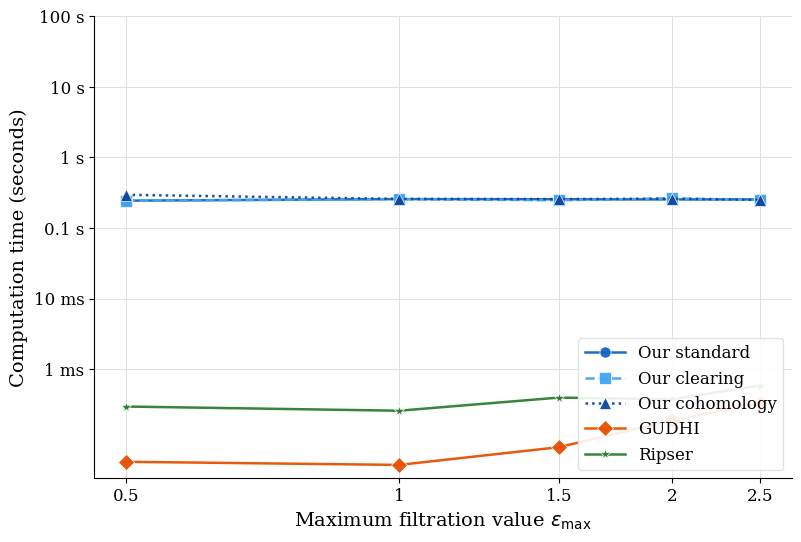

Saved -> ../figures/scope_time_cube.png


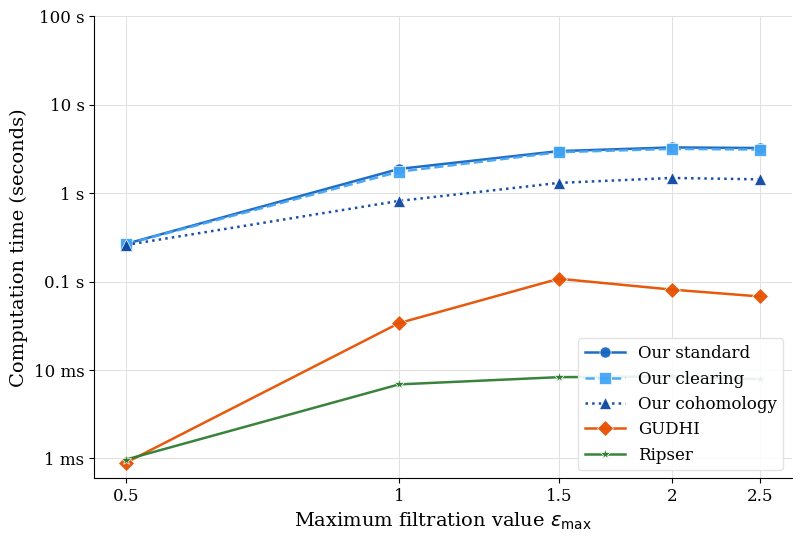

In [21]:
for dataset in ['Circle', 'Sphere', 'Torus', 'Cube']:
    sub = scope_df[scope_df['dataset'] == dataset]
    plot_loglog_scaling(
        sub,
        quantity='time',
        xaxis='max_eps',
        title=f'',  # Computation time vs scope, {dataset}
        savepath=f'{FIGURES}/scope_time_{dataset.lower()}.png',
    )
    plt.show()

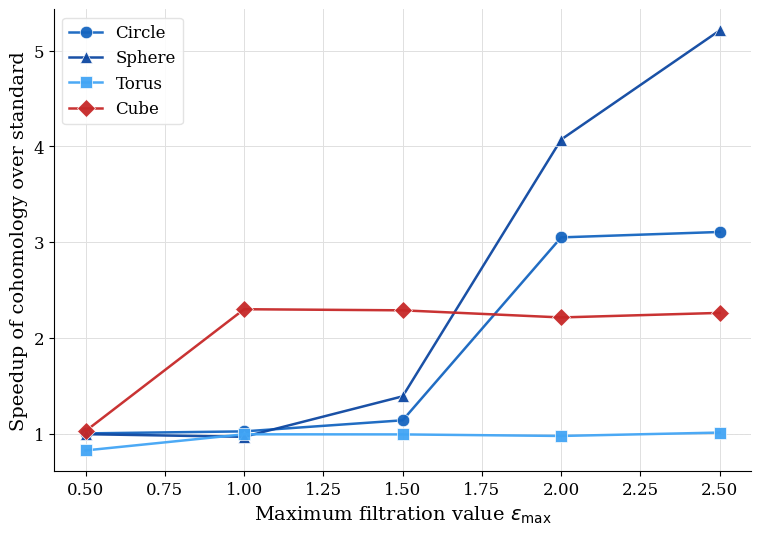

In [22]:
DATASET_COLOR = {
    'Circle': '#1565C0',
    'Sphere': '#0D47A1',
    'Torus':  '#42A5F5',
    'Cube':   '#C62828',
}
DATASET_MARKER = {
    'Circle': 'o',
    'Sphere': '^',
    'Torus':  's',
    'Cube':   'D',
}

fig, ax = plt.subplots(figsize=(9, 6))

for dataset in ['Circle', 'Sphere', 'Torus', 'Cube']:
    sub = scope_df[scope_df['dataset'] == dataset]
    std = sub[sub.method == 'our_standard'].set_index('max_eps')['time_s']
    coh = sub[sub.method == 'our_cohomology'].set_index('max_eps')['time_s']
    common_eps = sorted(std.index.intersection(coh.index))
    speedup = [std[e] / coh[e] for e in common_eps]
    ax.plot(common_eps, speedup,
            label=dataset,
            color=DATASET_COLOR[dataset],
            marker=DATASET_MARKER[dataset],
            markersize=9,
            linewidth=1.8,
            markeredgecolor='white',
            markeredgewidth=0.5,
            alpha=0.95)

ax.set_xlabel(r'Maximum filtration value $\varepsilon_{\max}$')
ax.set_ylabel('Speedup of cohomology over standard')
ax.axhline(1.0, color='gray', lw=0.7, ls='--', alpha=0.6, zorder=0)
ax.grid(True, which='major', color='#E0E0E0', lw=0.7, zorder=0)
ax.legend(loc='upper left', framealpha=0.9, edgecolor='#E0E0E0')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

# Currently linear y-axis. If the sphere curve dominates the figure visually,
# uncomment to switch to log:
# ax.set_yscale('log')

fig.savefig(f'{FIGURES}/scope_speedup.png', dpi=160, bbox_inches='tight')
plt.show()